In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns

In [3]:
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [4]:
# 소수점 아래 10자리까지 출력
pd.options.display.float_format = '{:.10f}'.format

In [5]:
ns = 1e-9

In [1]:
# /home/ehdgus7279/mgvm/results/mesh-6x6/20260525-222553/memory-traces/lud_mesh_6x6_memory_trace.csv

In [8]:
date = "20260525-222553"
trace_dir=f'{username}/mgvm/results/mesh-6x6/{date}/memory-traces'
print(f"{trace_dir}")

/home/ehdgus7279/mgvm/results/mesh-6x6/20260525-222553/memory-traces


In [11]:
benchmark = 'spmv' 
trace_file = f"{trace_dir}/{benchmark}_mesh_6x6_memory_trace.csv"

df = pd.read_csv(trace_file, skipinitialspace=True)
df = df.drop_duplicates()
df

,time,addr,pc,owner,rw,rdma,vector,type,chiplet,data_id,is_ptw
0,0.0153172160,2526825592,377016576,28,0,1,0,1,0,-1,1
1,0.0153172220,2526825584,377016584,28,0,1,0,1,0,-1,1
2,0.0153172360,2525011968,377016576,0,0,0,0,2,0,-1,0
3,0.0153172360,2525011968,377016576,0,0,0,0,0,0,-1,0
4,0.0153172380,2525011968,377016576,0,0,0,0,0,0,-1,0
...,...,...,...,...,...,...,...,...,...,...,...
244989097,0.0184951940,2323703744,377016908,24,0,1,1,2,9,1,0
244989098,0.0184951950,2333303536,377016908,27,0,1,0,1,26,-1,1
244989099,0.0184951950,2260430848,377016848,31,0,0,1,7,31,0,0
244989100,0.0184951950,2260430848,377016848,31,0,0,1,2,31,0,0


In [ ]:
rdma_df = df[df['rdma']==True]
rdma_df

,time,addr,pc,owner,rw,rdma,vector,type,chiplet
0,0.0430987970,3211534336,1061167360,0,0,1,0,0,19
1,0.0430987990,3211534336,1061167360,0,0,1,0,0,19
2,0.0430988010,3211534336,1061167360,0,0,1,0,0,19
3,0.0430988030,3211534336,1061167360,0,0,1,0,0,19
4,0.0430988150,3211534336,1061167360,0,0,1,0,0,13
...,...,...,...,...,...,...,...,...,...
552254,0.0438787780,2149816000,1061192476,35,0,1,1,2,0
552255,0.0438787800,2149816064,1061192476,35,0,1,1,2,0
552257,0.0438796490,2149815936,1061192508,35,1,1,1,4,0
552258,0.0438796510,2149816000,1061192508,35,1,1,1,4,0


In [8]:
group_size = 64
rdma_df['group'] = rdma_df['addr'] // (64 * group_size)

/tmp/ipykernel_668541/174131419.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rdma_df['group'] = rdma_df['addr'] // (64 * group_size)


In [16]:
# 4. PC별 통계 계산
# pc_hop_avg = df.groupby('pc')['hop_count'].mean().reset_index(name='hop_count_mean')
group_counts = rdma_df.groupby(['pc', 'group']).size().reset_index(name='access_count')
shared_map = rdma_df.groupby('group')['chiplet'].nunique().reset_index(name='shared_degree')

stats_df = pd.merge(group_counts, shared_map, on='group', how='left')

pc_stats_df = stats_df.groupby('pc').agg({
    'group': 'nunique',
    'access_count': ['sum', 'mean', 'std', 'median', 'max', 'min'],
    'shared_degree': ['mean', 'std', 'median', 'max', 'min']
}).reset_index()

pc_stats_df.columns = ['_'.join(col).strip('_') for col in pc_stats_df.columns.values]

pc_stats_df

,pc,group_nunique,access_count_sum,access_count_mean,access_count_std,access_count_median,access_count_max,access_count_min,shared_degree_mean,shared_degree_std,shared_degree_median,shared_degree_max,shared_degree_min
0,948961536,1,140,140.0000000000,NaN,140.0000000000,140,140,35.0000000000,NaN,35.0000000000,35,35
1,948961556,1,140,140.0000000000,NaN,140.0000000000,140,140,35.0000000000,NaN,35.0000000000,35,35
2,948961696,1770,110416,62.3819209040,7.3852947509,64.0000000000,64,16,1.8508474576,0.4362228861,2.0000000000,3,1
3,948961716,1765,107996,61.1875354108,9.7731330831,64.0000000000,64,4,1.8532577904,0.4344789721,2.0000000000,3,1
4,948961724,15,45,3.0000000000,3.0705978943,2.0000000000,13,1,1.4000000000,0.8280786712,1.0000000000,3,1
5,948961732,7,15,2.1428571429,0.8997354108,2.0000000000,3,1,1.2857142857,0.7559289460,1.0000000000,3,1
6,948961736,9,32,3.5555555556,1.3333333333,3.0000000000,6,2,1.2222222222,0.6666666667,1.0000000000,3,1
7,948961744,87,2328,26.7586206897,18.6821426472,16.0000000000,64,4,1.8390804598,0.9629601071,1.0000000000,3,1
8,948961760,1770,94952520,53645.4915254237,10812.5786744916,55038.5000000000,74944,11957,1.8508474576,0.4362228861,2.0000000000,3,1
9,948961764,1768,6210921,3512.9643665158,3543.1628861164,2310.5000000000,21005,11,1.8518099548,0.4355289430,2.0000000000,3,1


In [9]:
shared_chiplets = rdma_df.groupby('group').agg({
    'group': 'count',    # 해당 주소로의 총 접근 횟수
    'chiplet': 'nunique' # 공유된 칩렛 수
}).rename(columns={
    'group': 'access_count', 
    'chiplet': 'unique_chiplets'
}).reset_index()

shared_chiplets

,group,access_count,unique_chiplets
0,524305,160,1
1,524306,161,1
2,524307,162,1
3,524308,161,1
4,524309,161,1
...,...,...,...
999,784067,140,35
1000,784069,140,35
1001,784070,140,35
1002,784072,140,35


In [10]:
shared_group = shared_chiplets[shared_chiplets['unique_chiplets'] >= 2]
shared_group

,group,access_count,unique_chiplets
366,524672,209,2
382,524688,317,2
397,524703,233,2
398,524704,353,2
413,524719,341,2
...,...,...,...
999,784067,140,35
1000,784069,140,35
1001,784070,140,35
1002,784072,140,35


In [11]:
df_agg = rdma_df[rdma_df['group'].isin(shared_group['group'])].groupby('group').agg({
    'chiplet': 'unique',
}).reset_index()

In [ ]:
import pandas as pd
import numpy as np
from itertools import combinations

# 1. 6x6 Mesh 거리 계산 함수 (ID만 사용)
def calculate_hop(id1, id2):
    # x = id % 6, y = id // 6
    return abs(id1 % 6 - id2 % 6) + abs(id1 // 6 - id2 // 6)

# 2. 스크린샷의 데이터프레임을 'df_agg'라고 가정합니다.
def process_group_distances(chiplet_list):
    if len(chiplet_list) < 2:
        return 0, 0 # 칩렛이 하나면 거리는 0
    
    # 칩렛 ID들 간의 모든 가능한 쌍(Pair) 생성
    pairs = list(combinations(chiplet_list, 2))
    
    # 모든 쌍에 대해 Hop Count 계산
    dists = [calculate_hop(p1, p2) for p1, p2 in pairs]
    
    # 평균 거리와 최대 거리 반환
    return np.mean(dists), np.max(dists)

# 3. 데이터프레임에 적용 (df_agg는 스크린샷의 결과물)
# 'chiplet' 컬럼의 리스트를 순회하며 계산합니다.
df_agg[['avg_hop', 'max_hop']] = df_agg['chiplet'].apply(
    lambda x: pd.Series(process_group_distances(x))
)

df_agg['num_chiplets'] = df_agg['chiplet'].apply(len)

# 4. 결과 확인
print(df_agg[['group', 'chiplet', 'avg_hop', 'max_hop']].head())

    group  chiplet      avg_hop      max_hop
0  524672  [24, 0] 4.0000000000 4.0000000000
1  524688  [25, 0] 5.0000000000 5.0000000000
2  524703  [26, 0] 6.0000000000 6.0000000000
3  524704  [26, 0] 6.0000000000 6.0000000000
4  524719  [27, 0] 7.0000000000 7.0000000000


In [46]:
shared_chiplets = rdma_df.groupby('addr').agg({
    'addr': 'count',    # 해당 주소로의 총 접근 횟수
    'chiplet': 'nunique' # 공유된 칩렛 수
}).rename(columns={
    'addr': 'access_count', 
    'chiplet': 'unique_chiplets'
}).reset_index()

shared_chiplets

,addr,access_count,unique_chiplets
0,2147487744,265,15
1,2147487808,306,15
2,2147487872,277,15
3,2147487936,246,15
4,2147488000,200,15
...,...,...,...
674770,3098331968,276,1
674771,3098332032,276,1
674772,3098332096,276,1
674773,3098550272,75,15


In [47]:
shared_chiplets[shared_chiplets['unique_chiplets'] >= 2]

,addr,access_count,unique_chiplets
0,2147487744,265,15
1,2147487808,306,15
2,2147487872,277,15
3,2147487936,246,15
4,2147488000,200,15
...,...,...,...
1935,2149225728,23,4
1936,2149225792,17,3
1937,2149225856,9,2
674773,3098550272,75,15


In [12]:
import pandas as pd

# 설정: 그룹화할 단위 (예: 64B 캐시라인 16개를 묶어 1KB 단위로 분석)
CACHE_LINE_SIZE = 64
GROUP_SIZE = 16 
BIN_SIZE = CACHE_LINE_SIZE * GROUP_SIZE

# 1. 주소를 BIN_SIZE 단위로 나누어 'block_addr' 생성
df['block_addr'] = df['addr'] // BIN_SIZE

# 2. 각 블록 주소별로 접근한 칩렛의 고유 개수(nunique) 계산
# 'chiplet_id'는 칩렛 번호가 담긴 컬럼명으로 수정해서 사용하세요.
block_analysis = df.groupby('block_addr')['chiplet'].nunique().reset_index()
block_analysis.columns = ['block_addr', 'chiplet_nunique']

# 3. 결과 요약 (nunique 분포 확인)
print(block_analysis['chiplet_nunique'].value_counts(normalize=True))

# 4. nunique가 2 이상인(공유가 발생하는) 블록만 추출
shared_blocks = block_analysis[block_analysis['chiplet_nunique'] > 1]
print(f"Total Shared Blocks: {len(shared_blocks)} / {len(block_analysis)}")

chiplet_nunique
1    0.5275310835
2    0.4689165187
3    0.0028419183
36   0.0007104796
Name: proportion, dtype: float64
Total Shared Blocks: 3990 / 8445


In [39]:
df['cycle'] = df['time'] / ns
df['cycle'] = df['cycle'].astype(int)

In [90]:
df['cacheline'] = df['addr'] // 64

In [88]:
# 필터링 부분 (주석 처리된 복합 조건도 사용 가능하게 정리)
# rdma_df = df[df['rdma'] == True]
# 만약 특정 type만 보고 싶다면 아래 주석 해제
rdma_df = df[(df['rdma'] == True) & (df['type'].isin([2, 5]))]

# 수정된 집계 코드
shared_chiplets = rdma_df.groupby('addr').agg({
    'addr': 'count',    # 접근 횟수
    'chiplet': 'nunique' # 공유된 칩렛 수
}).rename(columns={     # columns= 키워드 반드시 필요
    'addr': 'access_count', 
    'chiplet': 'unique_chiplets'
}).reset_index()

In [95]:
shared_chiplets['cacheline'].nunique()

4086450

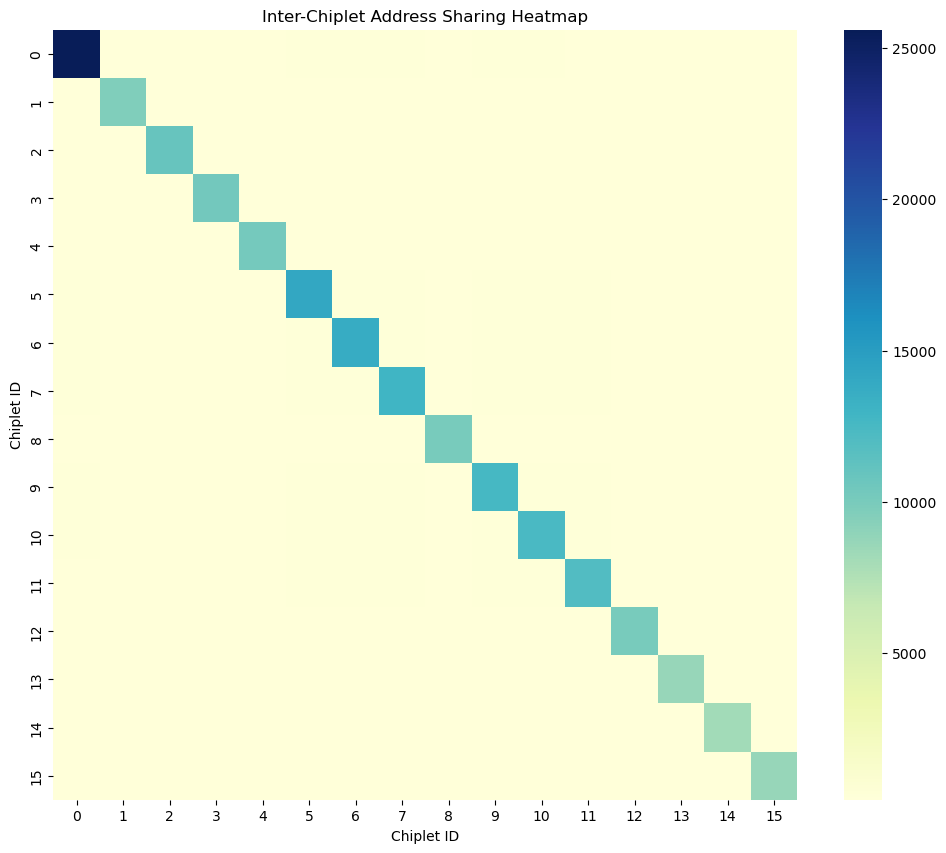

In [54]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_chiplet_similarity(df, bin_size=4096):
    # 1. 주소를 일정 단위(예: 4KB 페이지)로 묶어서 분석 데이터 축소
    df['addr_bin'] = df['addr'] // bin_size
    
    # 2. 각 칩렛별로 접근한 고유 주소 버킷 세트 생성
    chiplet_sets = df.groupby('chiplet')['addr_bin'].apply(set).to_dict()
    chiplets = sorted(chiplet_sets.keys())
    n = len(chiplets)
    
    # 3. 유사도 행렬 초기화 (n x n)
    # 여기서는 교집합의 크기를 사용 (얼마나 많은 주소 영역을 공유하는가)
    similarity_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(i, n):
            c1, c2 = chiplets[i], chiplets[j]
            # if c1 == c2:
            #     continue
            # 두 칩렛이 공통으로 접근한 주소 버킷의 개수
            intersection = len(chiplet_sets[c1].intersection(chiplet_sets[c2]))
            
            # (옵션) Jaccard 유사도로 정규화하고 싶다면:
            # union = len(chiplet_sets[c1].union(chiplet_sets[c2]))
            # score = intersection / union if union > 0 else 0
            
            similarity_matrix[i, j] = intersection
            similarity_matrix[j, i] = intersection
            
    return chiplets, similarity_matrix

# 실행 및 시각화
chiplets, matrix = analyze_chiplet_similarity(df, bin_size=64*4) # 캐시라인 단위 분석

plt.figure(figsize=(12, 10))
sns.heatmap(matrix, annot=False, cmap='YlGnBu', 
            xticklabels=chiplets, yticklabels=chiplets)
plt.title('Inter-Chiplet Address Sharing Heatmap')
plt.xlabel('Chiplet ID')
plt.ylabel('Chiplet ID')
plt.show()

In [ ]:
df[df['cacheline']==37790139]

,time,addr,pc,owner,rw,rdma,vector,type,chiplet,cacheline
12699763,0.0120425630,2418568896,268477156,32,0,1,1,2,21,37790139
12706329,0.0120435980,2418568896,268477172,32,1,1,1,4,21,37790139
26627974,0.0141353270,2418568896,268530404,32,0,1,1,2,21,37790139
26636932,0.0141366990,2418568896,268530420,32,1,1,1,4,21,37790139
40077427,0.0159516200,2418568896,268583652,32,0,1,1,2,21,37790139
40087138,0.0159526930,2418568896,268583668,32,1,1,1,5,21,37790139
56171517,0.0184124220,2418568896,268636896,32,0,1,1,2,21,37790139
56175052,0.0184134190,2418568896,268636916,32,1,1,1,5,21,37790139


: 

In [93]:
shared_1 = shared_chiplets[(shared_chiplets['unique_chiplets'] == 1)]['access_count'].sum()
shared_2_4 = shared_chiplets[(shared_chiplets['unique_chiplets'] >= 2) &
                            (shared_chiplets['unique_chiplets'] <= 4)]['access_count'].sum()
shared_5_8 = shared_chiplets[(shared_chiplets['unique_chiplets'] > 4) &
                            (shared_chiplets['unique_chiplets'] <= 8)]['access_count'].sum()
shared_9_16 = shared_chiplets[(shared_chiplets['unique_chiplets'] > 8) &
                             (shared_chiplets['unique_chiplets'] <= 16)]['access_count'].sum()
shared_17_plus = shared_chiplets[(shared_chiplets['unique_chiplets'] > 16)]['access_count'].sum()

print(f"1 chiplet: {shared_1}")
print(f"2-4 chiplets: {shared_2_4}")
print(f"5-8 chiplets: {shared_5_8}")
print(f"9-16 chiplets: {shared_9_16}")
print(f"17+ chiplets: {shared_17_plus}")

1 chiplet: 24503018
2-4 chiplets: 710542
5-8 chiplets: 2418
9-16 chiplets: 80027
17+ chiplets: 946493


In [89]:
shared_1 = shared_chiplets[(shared_chiplets['unique_chiplets'] == 1)]['addr'].nunique()
shared_2_4 = shared_chiplets[(shared_chiplets['unique_chiplets'] >= 2) &
                            (shared_chiplets['unique_chiplets'] <= 4)]['addr'].nunique()
shared_5_8 = shared_chiplets[(shared_chiplets['unique_chiplets'] > 4) &
                            (shared_chiplets['unique_chiplets'] <= 8)]['addr'].nunique()
shared_9_16 = shared_chiplets[(shared_chiplets['unique_chiplets'] > 8) &
                             (shared_chiplets['unique_chiplets'] <= 16)]['addr'].nunique()
shared_17_plus = shared_chiplets[(shared_chiplets['unique_chiplets'] > 16)]['addr'].nunique()

print(f"1 chiplet: {shared_1}")
print(f"2-4 chiplets: {shared_2_4}")
print(f"5-8 chiplets: {shared_5_8}")
print(f"9-16 chiplets: {shared_9_16}")
print(f"17+ chiplets: {shared_17_plus}")

1 chiplet: 3940108
2-4 chiplets: 114941
5-8 chiplets: 256
9-16 chiplets: 3547
17+ chiplets: 27598


In [8]:
clusters_3x3 = {
    'cluster_0_3x3': [0, 1, 2, 6, 7, 8, 12, 13, 14],
    'cluster_1_3x3': [3, 4, 5, 9, 10, 11, 15, 16, 17],
    'cluster_2_3x3': [18, 19, 20, 24, 25, 26, 30, 31, 32],
    'cluster_3_3x3': [21, 22, 23, 27, 28, 29, 33, 34, 35],
}

chiplet_to_cluster = {
    chiplet: cluster 
    for cluster, chiplets in clusters_3x3.items() 
    for chiplet in chiplets
}

df['cluster_3x3'] = df['chiplet'].map(chiplet_to_cluster).fillna('unknown')

In [23]:
df['owner_cluster_3x3'] = df['owner'].map(chiplet_to_cluster).fillna('unknown')

In [26]:
rdma_df = df[df['rdma'] == True]

remote_cluster_df = rdma_df[rdma_df['cluster_3x3'] != rdma_df['owner_cluster_3x3']]

addr_metrics_df = remote_cluster_df.groupby("addr").agg({
    'cluster_3x3': 'nunique',  # 데이터를 빌려간 외부 클러스터 수
    'chiplet': 'nunique',      # 데이터를 빌려간 외부 칩렛 수
    'addr': 'count'            # 외부에서 발생한 총 접근 횟수
}).rename(columns={
    'cluster_3x3': 'shared_clusters', 
    'chiplet': 'shared_chiplets',
    'addr': 'access_count'
}).reset_index()

In [ ]:
top_3x3_cluster_shared_df = addr_metrics_df[addr_metrics_df['shared_clusters']>=3]

top_shared_df = rdma_df[rdma_df['addr'].isin(top_3x3_cluster_shared_df['addr'])]

top_shared_df['addr'].value_counts().sum()

np.int64(1718842)

In [22]:
top_3x3_cluster_shared_df = addr_metrics_df[addr_metrics_df['shared_clusters']>=2]

top_shared_df = rdma_df[rdma_df['addr'].isin(top_3x3_cluster_shared_df['addr'])]

top_shared_df['addr'].value_counts().sum()

np.int64(1722855)

In [18]:
len(df[df['rdma']==True])

8125406

In [ ]:
top_shared_df['inter_arrival'] = top_shared_df.groupby(['addr', 'chiplet'])['cycle'].diff()
inter_arrival_df = top_shared_df.dropna(subset=['inter_arrival'])

inter_per_addr_stats = inter_arrival_df.groupby('addr')['inter_arrival'].agg(['mean', 'median', 'std', 'max', 'min'])

/tmp/ipykernel_3018984/1941668184.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_shared_df['inter_arrival'] = top_shared_df.groupby(['addr', 'chiplet'])['cycle'].diff()


In [ ]:
count_per_chiplet_df = df.groupby(['addr', 'chiplet']).agg(
    count=('addr', 'count'),
).rename({'addr': 'access_count'}).reset_index()

count_per_chiplet_df[count_per_chiplet_df['count'] > 1]['addr'].nunique()

69263

In [ ]:
count_per_chiplet_df['count'].sum()

In [131]:
df['addr'].nunique()

135001

In [ ]:
n_cycles=10000

first_appearance = df.groupby(['owner', 'pc'])['cycle'].min().reset_index()
first_appearance.columns = ['owner', 'pc', 'first_cycle']

df_with_start = df.merge(first_appearance, on=['owner', 'pc'], how='left')

phase_df = df_with_start[
    (df_with_start['cycle'] >= df_with_start['first_cycle']) & 
    (df_with_start['cycle'] < (df_with_start['first_cycle'] + n_cycles))
].copy()

In [111]:
shared_map = phase_df.groupby(['owner', 'addr'])['chiplet'].nunique().reset_index(name='shared_degree')

phase_df = phase_df.merge(shared_map, on=['owner', 'addr'], how='left')

In [112]:
pc_stats = phase_df.groupby(['owner', 'pc']).agg(
    access_count=('addr', 'count'),
    unique_addr_count=('addr', 'nunique'),
    shared_degree=('shared_degree', 'mean'),
).rename({
    'access_count': 'access_count',
    'unique_addr_count': 'unique_addr_count',
    'shared_degree': 'shared_degree',
}).reset_index()

pc_final_avg = pc_stats.groupby('pc').agg({
    'access_count': 'mean',
    'unique_addr_count': 'mean',
    'shared_degree': 'mean',
}).reset_index()

pc_final_avg['avg_access_count'] = pc_final_avg['access_count'] / pc_final_avg['unique_addr_count']

pc_final_avg

,pc,access_count,unique_addr_count,shared_degree,avg_access_count
0,571330816,144.0000000000,1.0000000000,36.0000000000,144.0000000000
1,571330836,144.0000000000,1.0000000000,36.0000000000,144.0000000000
2,571330968,4764.5714285714,3645.4285714286,1.0649245651,1.3069989811
3,571330988,517.8571428571,466.4761904762,1.0651214203,1.1101469988
4,571330996,46.6666666667,46.1428571429,1.0580446867,1.0113519092
5,571331004,46.5238095238,46.1428571429,1.0325477496,1.0082559340
6,571331012,23.3333333333,23.2380952381,1.0259782888,1.0040983607
7,571331016,33.7142857143,33.5714285714,1.0264261507,1.0042553191
8,571331020,34.8095238095,34.6666666667,1.0432268436,1.0041208791
9,571331024,38.9523809524,38.4761904762,1.0358135062,1.0123762376


In [57]:
import pandas as pd
import numpy as np

# 2. 시간 간격(Window) 설정
# 전체 데이터를 100개의 구간으로 나눕니다.
df['time_bin'] = pd.cut(df['time'], bins=100)

# 3. 1차 집계: (시간대, Owner, PC)별 총 접근 횟수 및 고유 캐시라인 수 계산
# 각 그룹 내에서 전체 행 개수(count)와 중복을 제외한 cacheline 개수(nunique)를 구합니다.
pc_stats = df.groupby(['time_bin', 'pc'], observed=False).agg(
    total_access=('addr', 'count'),
    unique_cachelines=('addr', 'nunique')
).reset_index()

# 4. 각 PC별 평균 접근 횟수 계산 (Total / Unique)
pc_stats['avg_per_line'] = pc_stats['total_access'] / pc_stats['unique_cachelines']

# 5. 2차 집계: (시간대, PC)별로 칩렛(owner)들 간의 평균 접근 횟수에 대한 통계(Mean, Std)
# 여러 owner(칩렛)가 동일한 PC를 실행할 때, 그들 사이의 접근 강도 분포를 확인합니다.
analysis_result = pc_stats.groupby(['time_bin', 'pc'], observed=False)['avg_per_line'].agg(
    mean_access='mean',
    std_access='std'
).reset_index()

# 데이터가 1개뿐이라 발생하는 NaN(표준편차)을 0으로 처리
analysis_result['std_access'] = analysis_result['std_access'].fillna(0)

# 결과 확인
analysis_result

,time_bin,pc,mean_access,std_access
0,"(0.0153, 0.0156]",377016576,144.0000000000,0.0000000000
1,"(0.0153, 0.0156]",377016584,144.0000000000,0.0000000000
2,"(0.0153, 0.0156]",377016732,1.1120274461,0.0000000000
3,"(0.0153, 0.0156]",377016740,1.0050953010,0.0000000000
4,"(0.0153, 0.0156]",377016744,1.0284062758,0.0000000000
...,...,...,...,...
2195,"(0.0405, 0.0407]",377016900,1.0000000000,0.0000000000
2196,"(0.0405, 0.0407]",377016904,1.0000000000,0.0000000000
2197,"(0.0405, 0.0407]",377016908,1.7976744186,0.0000000000
2198,"(0.0405, 0.0407]",377016916,1.1344856988,0.0000000000


In [70]:
import pandas as pd

# 1. 전처리: 캐시라인 번호 생성 (64B 기준)
df['cacheline'] = df['addr'] // 64

# 2. 시간 구간 설정
# 데이터의 밀도에 따라 bins 숫자를 조절하세요.
df['time_bin'] = pd.cut(df['time'], bins=100)
# 각 구간의 중간값을 대표 시간으로 설정
df['time_mid'] = df['time_bin'].apply(lambda x: x.mid).astype(float)

# 3. 누적 데이터를 저장할 리스트
cumulative_records = []

# 4. PC별로 루프를 돌며 누적 데이터 계산
# 전체를 한꺼번에 계산하는 것보다 PC별로 시계열을 처리하는 것이 빠릅니다.
for pc, pc_group in df.groupby('pc'):
    # 해당 PC의 데이터를 시간 순으로 정렬
    pc_group = pc_group.sort_values('time')
    
    # 시간 구간별로 순회
    unique_cachelines = set()
    total_access_count = 0
    
    # 각 시간 구간(bin)별로 누적치 계산
    # 구간의 순서를 보장하기 위해 sorted 사용
    time_steps = sorted(pc_group['time_mid'].unique())
    
    for t in time_steps:
        # 해당 구간(t)에 속하는 데이터 추출
        current_bin_data = pc_group[pc_group['time_mid'] == t]
        
        # 누적 접근 횟수 업데이트
        total_access_count += len(current_bin_data)
        
        # 누적 고유 캐시라인 세트에 추가
        unique_cachelines.update(current_bin_data['cacheline'].tolist())
        
        # 결과 기록
        cumulative_records.append({
            'time': t,
            'pc': pc,
            'cum_access_count': total_access_count,
            'cum_unique_cachelines': len(unique_cachelines),
            'cum_avg_access_per_line': total_access_count / len(unique_cachelines)
        })

# 5. 결과 데이터프레임 생성
cum_df = pd.DataFrame(cumulative_records)

# 6. CSV나 엑셀로 저장하려면 아래 주석 해제
# cum_df.to_csv("cumulative_pc_analysis.csv", index=False)

cum_df.head()

,time,pc,cum_access_count,cum_unique_cachelines,cum_avg_access_per_line
0,0.0154500000,377016576,144,1,144.0000000000
1,0.0154500000,377016584,144,1,144.0000000000
2,0.0154500000,377016732,134840,121256,1.1120274461
3,0.0154500000,377016740,5326,5299,1.0050953010
4,0.0154500000,377016744,6227,6055,1.0284062758


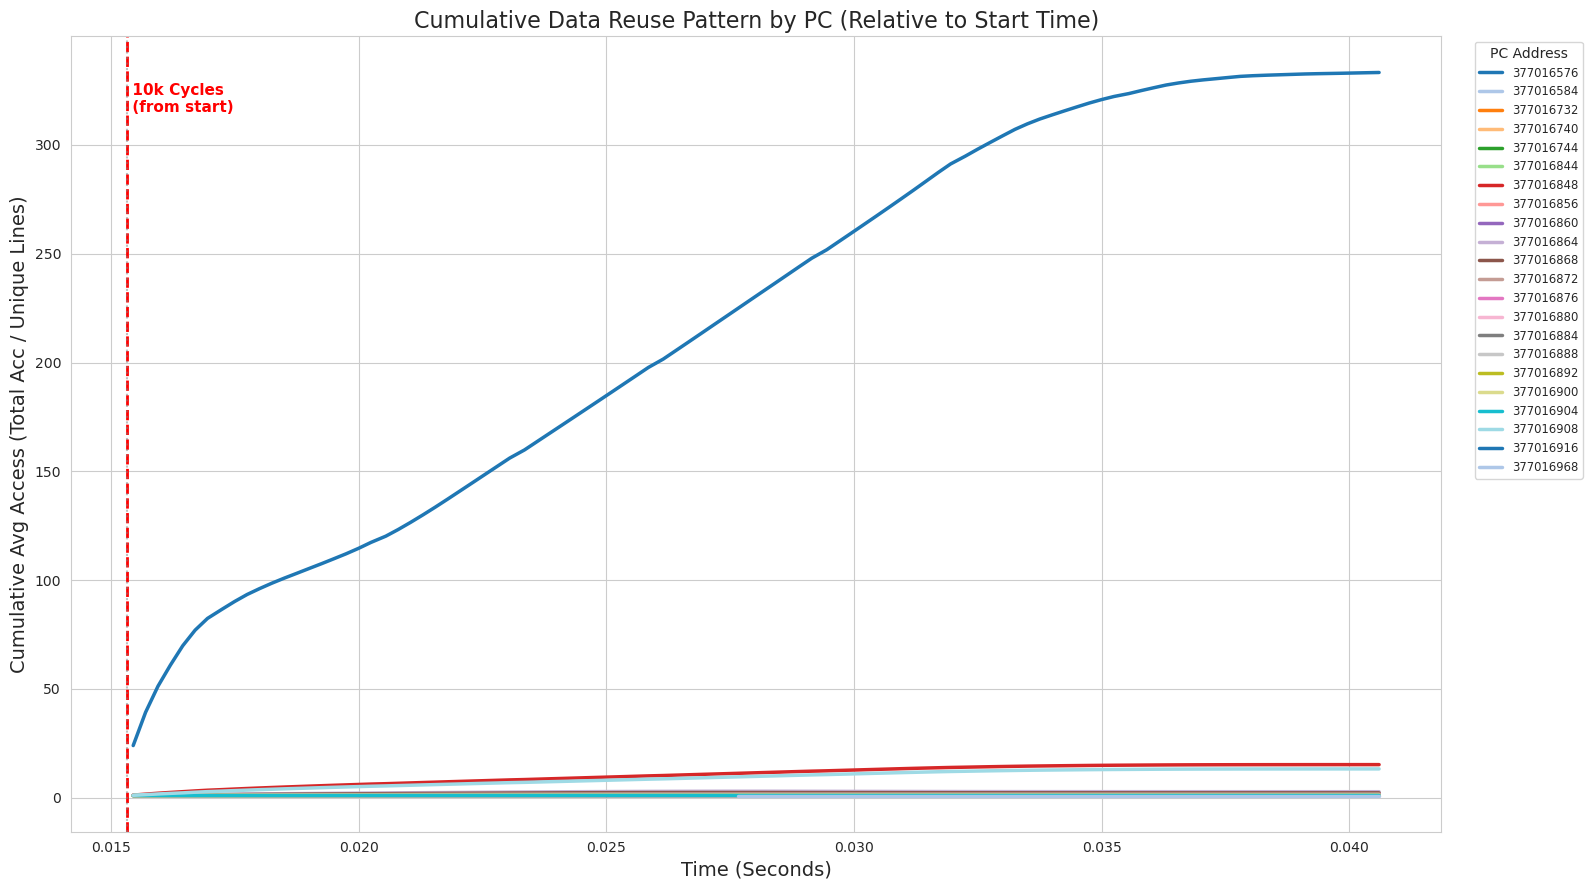

In [ ]:
# 1. 주파수 설정 및 시작 시간 파악
frequency = 1e9  # 1GHz 가정
cycle_10k_delta = 10000 / frequency

# 데이터상에서 실제 연산이 시작된 첫 시간 추출
start_time = df['time'].min() 
target_time = start_time + cycle_10k_delta

# 2. 시각화
plt.figure(figsize=(16, 9))
sns.set_style("whitegrid")

# 기존 누적 데이터 그래프
sns.lineplot(data=cum_df, x='time', y='cum_avg_access_per_line', hue='pc', palette='tab20', linewidth=2.5)

# 3. 시작 시간 기준 1만 사이클 지점에 수직선 추가
plt.axvline(x=target_time, color='red', linestyle='--', linewidth=2)

# 4. 수직선 라벨 추가 (위치 조정)
plt.text(target_time, plt.ylim()[1] * 0.9, f' 10k Cycles\n (from start)', 
         color='red', fontweight='bold', fontsize=11)

# 시작 시점도 참고용으로 흐리게 표시하고 싶다면 (선택 사항)
plt.axvline(x=start_time, color='gray', linestyle=':', alpha=0.5)

plt.title('Cumulative Data Reuse Pattern by PC (Relative to Start Time)', fontsize=16)
plt.xlabel('Time (Seconds)', fontsize=14)
plt.ylabel('Cumulative Avg Access (Total Acc / Unique Lines)', fontsize=14)
plt.legend(title='PC Address', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize='small')

plt.tight_layout()
plt.show()

In [ ]:
shared_map = df.groupby(['owner', 'pc'])['chiplet'].nunique().reset_index(name='shared_degree')
shared_map.groupby('pc')['shared_degree'].mean()

In [58]:
addr_counts = df.groupby(['owner', 'pc', 'addr']).size().reset_index(name='access_count')
shared_map = df.groupby('addr')['chiplet'].nunique().reset_index(name='shared_degree')

stats_df = pd.merge(addr_counts, shared_map, on='addr', how='left')

In [59]:
pc_stats_df = stats_df.groupby('pc').agg({
    'addr': 'nunique',
    'access_count': ['sum', 'mean', 'std', 'median', 'max', 'min'],
    'shared_degree': ['mean', 'std', 'median', 'max', 'min']
}).reset_index()

pc_stats_df

pc     addr access_count                               \
               nunique          sum           mean           std   
0   377016576        1          144 144.0000000000           NaN   
1   377016584        1          144 144.0000000000           NaN   
2   377016732   121256       134840   1.1120274461  0.3154015184   
3   377016740     5299         5326   1.0050953010  0.0712060092   
4   377016744     6055         6227   1.0284062758  0.1661442691   
5   377016844     3284         3293   1.0027405603  0.0522865385   
6   377016848  2748771     41845201  15.2232401317  1.8575281546   
7   377016856     7199         7342   1.0198638700  0.1405341824   
8   377016860    19171        19729   1.0291064629  0.1777619213   
9   377016864   425423      1180314   2.7744480200  1.9846658895   
10  377016868   615407      1391837   2.2616528574  1.5319629930   
11  377016872   502435       850201   1.6921611751  1.0267229919   
12  377016876   386235       529745   1.3715613551  0.6927472784   
13  377016880   272455       328803   1.2068158044  0.4957938695   
14  377016884   136425       142769   1.0465017409  0.2245520596   
15  377016888   228844       260596   1.1387495412  0.3984980332   
16  377016892   239579       269825   1.1262464573  0.3767484133   
17  377016900   208919       231386   1.1075392856  0.3449753720   
18  377016904   120666       126043   1.0445610197  0.2191169259   
19  377016908  2748634     36433330  13.2550677900  2.5021072713   
20  377016916   131073     43686179 333.2965523029 18.0844536150   
21  377016968   131072       131072   1.0000000000  0.0000000000   

                            shared_degree                                     
           median  max  min          mean          std        median max min  
0  144.0000000000  144  144 36.0000000000          NaN 36.0000000000  36  36  
1  144.0000000000  144  144 36.0000000000          NaN 36.0000000000  36  36  
2    1.0000000000    2    1  1.0002968925 0.0172280825  1.0000000000   2   1  
3    1.0000000000    2    1  1.0000000000 0.0000000000  1.0000000000   1   1  
4    1.0000000000    2    1  1.0000000000 0.0000000000  1.0000000000   1   1  
5    1.0000000000    2    1  1.0000000000 0.0000000000  1.0000000000   1   1  
6   16.0000000000   16    1  1.0000123692 0.0035169612  1.0000000000   2   1  
7    1.0000000000    3    1  1.0001389082 0.0117859315  1.0000000000   2   1  
8    1.0000000000    4    1  1.0001564864 0.0125087982  1.0000000000   2   1  
9    2.0000000000   14    1  1.0000775699 0.0088070437  1.0000000000   2   1  
10   2.0000000000   13    1  1.0000032499 0.0018027414  1.0000000000   2   1  
11   1.0000000000   11    1  1.0000019903 0.0014107825  1.0000000000   2   1  
12   1.0000000000    8    1  1.0000051782 0.0022755617  1.0000000000   2   1  
13   1.0000000000    7    1  1.0000036703 0.0019158108  1.0000000000   2   1  
14   1.0000000000    4    1  1.0000659703 0.0081219730  1.0000000000   2   1  
15   1.0000000000    6    1  1.0000087396 0.0029562713  1.0000000000   2   1  
16   1.0000000000    6    1  1.0000041740 0.0020430342  1.0000000000   2   1  
17   1.0000000000    5    1  1.0000047865 0.0021878172  1.0000000000   2   1  
18   1.0000000000    4    1  1.0000082873 0.0028787738  1.0000000000   2   1  
19  14.0000000000   16    1  1.0000123698 0.0035170488  1.0000000000   2   1  
20 333.0000000000  417    1 35.9963913239 0.1125817945 36.0000000000  36   1  
21   1.0000000000    1    1  1.0000000000 0.0000000000  1.0000000000   1   1

In [96]:
import pandas as pd

def calculate_owner_pc_saturation(df):
    # 1. (Owner, PC, 요청자) 조합별로 가장 빠른 시간 추출
    # src_chiplet: 요청을 보낸 주체 / owner: 요청을 받은 Home Node
    first_requests = df.groupby(['owner', 'pc', 'chiplet'])['time'].min().reset_index()
    
    # 2. Owner와 PC별로 시간순 정렬
    first_requests = first_requests.sort_values(by=['owner', 'pc', 'time'])
    
    # 3. 각 (Owner, PC) 그룹 내에서 유니크한 요청자(src_chiplet)의 누적 수 계산
    first_requests['cumulative_src_count'] = first_requests.groupby(['owner', 'pc']).cumcount() + 1
    
    # 4. 36번째 유니크한 요청자가 도착한 시점(Saturation) 필터링
    # 만약 본인 칩렛의 요청도 트레이스에 포함된다면 36, 제외라면 35로 설정
    saturation_points = first_requests[first_requests['cumulative_src_count'] == 18].copy()
    
    # 5. 결과 정리
    saturation_points = saturation_points.rename(columns={'time': 'saturation_time'})
    return saturation_points[['owner', 'pc', 'saturation_time']]

# 실행
saturation_df = calculate_owner_pc_saturation(df)

saturation_df.groupby('pc')['saturation_time'].mean()

pc
377016576   0.0153183390
377016584   0.0153183630
377016916   0.0159474883
Name: saturation_time, dtype: float64

In [ ]:
import pandas as pd

# 1. Saturation Time 계산 함수 (앞서 작성한 로직 활용)
def calculate_saturation_df(df, target_degree=18):
    # 각 (Owner, PC, 요청자)별 첫 방문 시간
    first_reqs = df.groupby(['owner', 'pc', 'chiplet'])['time'].min().reset_index()
    first_reqs = first_reqs.sort_values(['owner', 'pc', 'time'])
    
    # 누적 요청자 수 계산
    first_reqs['cum_src_count'] = first_reqs.groupby(['owner', 'pc']).cumcount() + 1
    
    # 목표 수치(예: 18)에 도달한 시점 필터링
    saturations = first_reqs[first_reqs['cum_src_count'] == target_degree].copy()
    return saturations.rename(columns={'time': 'saturation_time'})

# 2. Saturation 데이터 추출 및 PC별 평균 계산
saturation_df = calculate_saturation_df(df, target_degree=18)
pc_saturation_avg = saturation_df.groupby('pc')['saturation_time'].mean().reset_index()

# 3. 기존 PC 통계 계산 로직
addr_counts = df.groupby(['owner', 'pc', 'addr']).size().reset_index(name='access_count')
shared_map = df.groupby('addr')['chiplet'].nunique().reset_index(name='shared_degree')
stats_df = pd.merge(addr_counts, shared_map, on='addr', how='left')

pc_stats_df = stats_df.groupby('pc').agg({
    'addr': 'nunique',
    'access_count': ['sum', 'mean', 'std', 'median', 'max', 'min'],
    'shared_degree': ['mean', 'std', 'median', 'max', 'min']
}).reset_index()

# Multi-index 컬럼명 평탄화 (나중에 다루기 편하게)
pc_stats_df.columns = ['_'.join(col).strip('_') for col in pc_stats_df.columns.values]

# 4. 최종 통합: PC 통계 + Saturation Time
final_pc_report = pd.merge(pc_stats_df, pc_saturation_avg, on='pc', how='left')

# 결과 확인
final_pc_report

MergeError: Not allowed to merge between different levels. (2 levels on the left, 1 on the right)

: 

In [98]:
saturation_df.groupby('pc')['saturation_time'].mean()

pc
377016576   0.0153183390
377016584   0.0153183630
377016916   0.0159474883
Name: saturation_time, dtype: float64

In [32]:
df[(df['owner']==0) & 
   df['pc'].isin(saturation_df[saturation_df['owner']==0]['pc'])]['addr'].nunique()

3035

In [34]:
saturated_trace = pd.merge(
    df, 
    saturation_df[['owner', 'pc']], 
    on=['owner', 'pc'], 
    how='inner'
)

owner_unique_addr_counts = saturated_trace.groupby('owner')['addr'].nunique().reset_index()

owner_unique_addr_counts

,owner,addr
0,0,58300
1,1,59808
2,4,46600
3,5,2856
4,8,49974
5,9,46544
6,12,47097
7,13,2940
8,16,58707
9,17,52252


In [75]:
addr_counts = df['addr'].value_counts().reset_index()
addr_counts

,addr,count
0,3099382336,1198
1,3099382272,1198
2,3098063040,1198
3,3098062976,1198
4,3098068032,1198
...,...,...
1874932,2254568768,1
1874933,2254568704,1
1874934,2254568896,1
1874935,2276579072,1


In [76]:
count_df = pd.merge(df, addr_counts, on='addr', how='left')
count_df

,time,addr,pc,owner,rw,rdma,vector,type,chiplet,count
0,0.0385404110,3105370112,948961536,0,0,0,0,0,0,144
1,0.0385404130,3105370112,948961536,0,0,0,0,0,0,144
2,0.0385404150,3105370112,948961536,0,0,0,0,0,0,144
3,0.0385404170,3105370112,948961536,0,0,0,0,0,0,144
4,0.0385406930,3105374208,948961556,0,0,0,0,0,0,144
...,...,...,...,...,...,...,...,...,...,...
188746071,0.0397126900,3092993280,948961760,27,1,1,1,4,3,991
188746072,0.0397126900,3100422016,948961760,32,1,1,1,4,31,873
188746073,0.0397126900,2245373888,948961820,17,0,1,1,1,6,25
188746074,0.0397126900,2266317760,948961820,13,0,1,1,1,10,29


In [77]:
is_rw_addr = df.groupby('addr')['rw'].transform('max') == 1
rw_addrs = set(df.loc[is_rw_addr, 'addr']) # 쓰기가 발생한 주소들 (Set)

# Top 10% 주소들 추출
cutoff = int(len(df) * 0.10)
if cutoff == 0: cutoff = 1 # 최소 1개는 포함
addr_counts = addr_counts.sort_values(by='count', ascending=False).reset_index(drop=True)
top_10_addrs = addr_counts.head(cutoff)

# Top 10% 주소 중 rw_addrs(쓰기 발생 주소)에 포함되는 개수 확인
top_10_rw_df = df[df['addr'].isin(top_10_addrs['addr']) & df['addr'].isin(rw_addrs)]

In [78]:
top_10_rw_df

,time,addr,pc,owner,rw,rdma,vector,type,chiplet
36,0.0385413270,3090619392,948961696,27,0,1,1,2,0
37,0.0385413270,3090619456,948961696,27,0,1,1,2,0
38,0.0385413280,3095977984,948961696,0,0,0,1,2,0
39,0.0385413280,3095978048,948961696,0,0,0,1,2,0
40,0.0385413290,3090619520,948961696,27,0,1,1,2,0
...,...,...,...,...,...,...,...,...,...
188746069,0.0397126900,3089621760,948961760,11,1,1,1,4,3
188746070,0.0397126900,3094563776,948961760,15,1,1,1,4,3
188746071,0.0397126900,3092993280,948961760,27,1,1,1,4,3
188746072,0.0397126900,3100422016,948961760,32,1,1,1,4,31


In [83]:
df[df['addr']==3090619392]['rw'].value_counts()

rw
1    738
0      1
Name: count, dtype: int64

In [79]:
result = top_10_rw_df.groupby('addr')['rw'].value_counts().unstack(fill_value=0)
result.columns = ['read', 'write']
result.sum()

read        114688
write    110527071
dtype: int64

In [81]:
df.groupby('addr')['rw'].value_counts().unstack(fill_value=0).sum()

rw
0     78219005
1    110527071
dtype: int64

In [68]:
top_10_rw_df['time_bin'] = pd.cut(top_10_rw_df['time'], bins=100)

# 2. 시간 구간별로 rw(0, 1)의 개수를 집계합니다.
pivot_df = top_10_rw_df.groupby(['time_bin', 'rw']).size().unstack(fill_value=0)

# 3. 개수를 비율(Percentage)로 변환합니다.
pivot_df_ratio = pivot_df.div(pivot_df.sum(axis=1), axis=0)

/tmp/ipykernel_2178720/216202925.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_10_rw_df['time_bin'] = pd.cut(top_10_rw_df['time'], bins=100)
/tmp/ipykernel_2178720/216202925.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot_df = top_10_rw_df.groupby(['time_bin', 'rw']).size().unstack(fill_value=0)


In [7]:
total_counts = df['addr'].value_counts().reset_index()

top_10_percent_cutoff = int(len(total_counts) * 0.10)
top_10_counts = total_counts.head(top_10_percent_cutoff)

,addr,count
0,3209232384,16974
1,3211534336,144
2,3211538432,144
3,3211563008,144
4,3211558912,144
...,...,...
13495,2151455552,6
13496,2149317120,6
13497,2149318272,6
13498,2149318144,6


In [7]:
rdma_counts = df[(df['rdma']==True)]['addr'].value_counts().reset_index()
rdma_counts = rdma_counts.sort_values(by='count', ascending=False).reset_index(drop=True)

total_rdma_counts = rdma_counts['count'].sum()
total_remote_cachelines = rdma_counts['addr'].nunique()

rdma_streaming_counts = rdma_counts[rdma_counts['count'] <= 5]
total_rdma_streaming_counts = rdma_streaming_counts['count'].sum()
total_rdma_streaming_cachelines = rdma_streaming_counts['addr'].nunique()

top_10_percent_cutoff = int(len(rdma_counts) * 0.10)
total_rdma_top_10_percent_counts = rdma_counts.head(top_10_percent_cutoff)['count'].sum()
total_rdma_top_10_percent_cachelines = rdma_counts.head(top_10_percent_cutoff)['addr'].nunique()

print(f"Total RDMA counts: {total_rdma_counts}")
print(f"Total unique cache lines: {total_remote_cachelines}")
print(f"Average RDMA accesses per cache line: {total_rdma_counts / total_remote_cachelines:.2f}")

print (f"Total streaming RDMA counts: {total_rdma_streaming_counts}")
print(f"Total unique streaming RDMA cache lines: {total_rdma_streaming_cachelines}")

print(f"Total top 10% RDMA counts: {total_rdma_top_10_percent_counts}")
print(f"Total unique top 10% RDMA cache lines: {total_rdma_top_10_percent_cachelines}")
print(f"Average top 10% RDMA accesses per cache line: {total_rdma_top_10_percent_counts / total_rdma_top_10_percent_cachelines:.2f}")

print(f"max, min, mean, median: {rdma_counts['count'].max()}, {rdma_counts['count'].min()}, {rdma_counts['count'].mean():.2f}, {rdma_counts['count'].median()}")

Total RDMA counts: 179906972
Total unique cache lines: 1759523
Average RDMA accesses per cache line: 102.25
Total streaming RDMA counts: 2857
Total unique streaming RDMA cache lines: 861
Total top 10% RDMA counts: 110767301
Total unique top 10% RDMA cache lines: 175952
Average top 10% RDMA accesses per cache line: 629.53
max, min, mean, median: 1198, 1, 102.25, 46.0


In [8]:
local_counts = df[(df['rdma']==False)]['addr'].value_counts().reset_index()
local_counts = local_counts.sort_values(by='count', ascending=False).reset_index(drop=True)

total_local_counts = local_counts['count'].sum()
total_local_cachelines = local_counts['addr'].nunique()

local_streaming_counts = local_counts[local_counts['count'] <= 5]
total_local_streaming_counts = local_streaming_counts['count'].sum()
total_local_streaming_cachelines = local_streaming_counts['addr'].nunique()

top_10_percent_cutoff = int(len(local_counts) * 0.10)
total_local_top_10_percent_counts = local_counts.head(top_10_percent_cutoff)['count'].sum()
total_local_top_10_percent_cachelines = local_counts.head(top_10_percent_cutoff)['addr'].nunique()

print(f"Total local counts: {total_local_counts}")
print(f"Total unique cache lines: {total_local_cachelines}")

print(f"Total streaming local counts: {total_local_streaming_counts}")
print(f"Total unique streaming local cache lines: {total_local_streaming_cachelines}")

print(f"Total top 10% local counts: {total_local_top_10_percent_counts}")
print(f"Total unique top 10% local cache lines: {total_local_top_10_percent_cachelines}")
print(f"Average local accesses per cache line: {total_local_top_10_percent_counts / total_local_top_10_percent_cachelines:.2f}")

print(f"max, min, mean, median: {local_counts['count'].max()}, {local_counts['count'].min()}, {local_counts['count'].mean():.2f}, {local_counts['count'].median()}")

Total local counts: 8839104
Total unique cache lines: 119310
Total streaming local counts: 12471
Total unique streaming local cache lines: 3941
Total top 10% local counts: 4615512
Total unique top 10% local cache lines: 11931
Average local accesses per cache line: 386.85
max, min, mean, median: 1198, 1, 74.09, 44.0


In [17]:
local_df = df[df['rdma']==False]
local_stride_df = local_df.groupby(['chiplet'])['addr'].diff()
local_stride_df = local_stride_df.dropna().reset_index(drop=True)

local_stride_df.value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')

,addr,Ratio (%)
0,64.0000000000,16.3893659057
1,-64.0000000000,10.3010392825
2,128.0000000000,3.9979278384
3,192.0000000000,1.0194840435
4,320.0000000000,0.2453988702
...,...,...
167884,806876160.0000000000,0.0000113134
167885,-806858176.0000000000,0.0000113134
167886,-806861696.0000000000,0.0000113134
167887,-806861568.0000000000,0.0000113134


In [10]:
rdma_df = df[df['rdma']==True]
rdma_stride_df = rdma_df.groupby(['chiplet'])['addr'].diff()
rdma_stride_df = rdma_stride_df.dropna().reset_index(drop=True)

rdma_stride_df.value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')

,addr,Ratio (%)
0,64.0000000000,6.4729733377
1,-64.0000000000,5.1887426953
2,128.0000000000,0.4255511305
3,192.0000000000,0.1781543320
4,320.0000000000,0.0820407502
...,...,...
4349383,807228288.0000000000,0.0000005558
4349384,-804239936.0000000000,0.0000005558
4349385,836427584.0000000000,0.0000005558
4349386,-807232256.0000000000,0.0000005558


In [11]:
pc_stride_df = local_df.groupby(['chiplet', 'pc'])['addr'].diff().dropna()
pc_stride_df.value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')

,addr,Ratio (%)
0,64.0000000000,18.9507078920
1,-64.0000000000,9.7341736607
2,128.0000000000,5.0751925210
3,192.0000000000,1.1818941487
4,320.0000000000,0.3049290298
...,...,...
39737,816344128.0000000000,0.0000113138
39738,816341248.0000000000,0.0000113138
39739,823389888.0000000000,0.0000113138
39740,-823389824.0000000000,0.0000113138


In [52]:
pc_stride_df.value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')

,addr,Ratio (%)
0,64.0000000000,11.4312066200
1,-64.0000000000,2.1165243806
2,128.0000000000,1.1899566389
3,0.0000000000,0.7429352600
4,192.0000000000,0.2122106137
...,...,...
951281,-30584704.0000000000,0.0000038468
951282,30573184.0000000000,0.0000038468
951283,-30576256.0000000000,0.0000038468
951284,30575744.0000000000,0.0000038468


In [271]:
shared_map = df.groupby('addr')['chiplet'].nunique().reset_index(name='shared_degree')
shared_map

,addr,shared_degree
0,2147487744,1
1,2147487808,1
2,2147487872,1
3,2147487936,1
4,2147488000,1
...,...,...
8454223,2690138048,36
8454224,2690146304,36
8454225,2690150400,36
8454226,2690158592,36


In [12]:
report_dir=f'{username}/mgvm/results/reports'
sub_dir = "20260415-153843-mesh/data-allocation-logs"
data_log_dir = f"{report_dir}/{sub_dir}"
print(f"{data_log_dir}")

/home/ehdgus7279/mgvm/results/reports/20260415-153843-mesh/data-allocation-logs


In [13]:
data_alloc_file = f"{data_log_dir}/{benchmark}_mesh_6x6_data_allocation_log.csv"

df_alloc = pd.read_csv(data_alloc_file, skipinitialspace=True)
df_alloc

,DataID,ChipletID,StartAddr,EndAddr
0,0,10,2148143104,2148147200
1,0,10,2148147200,2148151296
2,0,10,2148151296,2148155392
3,0,10,2148155392,2148159488
4,0,10,2148159488,2148163584
...,...,...,...,...
231675,2,35,3095916544,3095920640
231676,2,35,3095920640,3095924736
231677,2,35,3098218496,3098222592
231678,2,35,3098222592,3098226688


In [275]:
addr_counts['count'].sum()

np.int64(155278054)

In [14]:
df = df.sort_values('addr')
df_alloc = df_alloc.sort_values('StartAddr')

df_trace_mapped = pd.merge_asof(
    df, 
    df_alloc[['StartAddr', 'EndAddr', 'DataID']], 
    left_on='addr', 
    right_on='StartAddr', 
    direction='backward'
)

mask = (df_trace_mapped['addr'] <= df_trace_mapped['EndAddr'])
df_trace_mapped.loc[~mask, 'DataID'] = -1

df = df_trace_mapped.drop(columns=['StartAddr', 'EndAddr'])
df

,time,addr,pc,owner,rw,rdma,vector,type,chiplet,DataID
0,0.0385495130,2147487744,948961776,0,0,1,1,1,7,0
1,0.0385538720,2147487744,948961776,0,0,1,1,0,5,0
2,0.0385538700,2147487744,948961776,0,0,1,1,0,5,0
3,0.0385578920,2147487744,948961776,0,0,1,1,2,33,0
4,0.0385478700,2147487744,948961776,0,0,1,1,2,7,0
...,...,...,...,...,...,...,...,...,...,...
188746071,0.0385437850,3105374208,948961556,0,0,1,0,0,21,-1
188746072,0.0385456700,3105374208,948961556,0,0,1,0,0,29,-1
188746073,0.0385417560,3105374208,948961556,0,0,1,0,0,2,-1
188746074,0.0385417540,3105374208,948961556,0,0,1,0,0,2,-1


In [16]:
df = df.sort_values(by='time')

local_df = df[df['rdma']==False]
local_stride_df = local_df.groupby(['chiplet', 'pc', 'DataID'])['addr'].diff()
local_stride_df = local_stride_df.dropna().reset_index(drop=True)

local_stride_df.value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')

,addr,Ratio (%)
0,64.0000000000,19.1311842517
1,-64.0000000000,11.0149760356
2,128.0000000000,5.1443189575
3,192.0000000000,1.2523305125
4,320.0000000000,0.2992740692
...,...,...
34668,16564224.0000000000,0.0000113139
34669,18923904.0000000000,0.0000113139
34670,18922368.0000000000,0.0000113139
34671,14194432.0000000000,0.0000113139


In [327]:
df = df.sort_values(by='time')

In [329]:
df['stride'] = df.groupby(['DataID', 'chiplet'])['addr'].diff()

In [333]:
strides = df['stride'].dropna()

stride_counts = strides.value_counts()
stride_ratios = strides.value_counts(normalize=True) * 100

result = pd.DataFrame({
    'Count': stride_counts,
    'Ratio (%)': stride_ratios
}).reset_index()

result

,stride,Count,Ratio (%)
0,64.0000000000,17632102,13.8199805885
1,128.0000000000,15777693,12.3665012255
2,192.0000000000,11301276,8.8579010571
3,-64.0000000000,11029205,8.6446527480
4,-128.0000000000,6520214,5.1105211910
...,...,...,...
686334,-12603712.0000000000,1,0.0000007838
686335,13845696.0000000000,1,0.0000007838
686336,-11622912.0000000000,1,0.0000007838
686337,-13897536.0000000000,1,0.0000007838


In [350]:
def plot_stride_ratio(df, top_n=5):
    # 1. DataID가 -1인 데이터 제외 및 비율 계산
    df_filtered = df[df['DataID'] != -1].copy()
    stride_ratios = df_filtered.groupby('DataID')['stride'].value_counts(normalize=True).mul(100).reset_index(name='Ratio (%)')
    
    # 2. 각 DataID별로 상위 N개와 Others 처리
    unique_ids = sorted(stride_ratios['DataID'].unique())
    processed_data = []

    for d_id in unique_ids:
        data_subset = stride_ratios[stride_ratios['DataID'] == d_id].sort_values(by='Ratio (%)', ascending=False)
        top_data = data_subset.head(top_n).copy()
        others_val = data_subset.iloc[top_n:]['Ratio (%)'].sum()
        
        if others_val > 0:
            others_row = pd.DataFrame({'DataID': [d_id], 'stride': ['Others'], 'Ratio (%)': [others_val]})
            top_data = pd.concat([top_data, others_row], ignore_index=True)
        
        processed_data.append(top_data)
    
    full_df = pd.concat(processed_data)

    # 3. 누적 막대 그래프를 위한 피벗 테이블 생성
    # 행: DataID, 열: stride, 값: Ratio (%)
    pivot_df = full_df.pivot(index='DataID', columns='stride', values='Ratio (%)').fillna(0)
    
    # stride 라벨 정렬 (Others를 맨 위로 보내기 위해)
    cols = [c for c in pivot_df.columns if c != 'Others']
    if 'Others' in pivot_df.columns:
        cols = cols + ['Others']
    pivot_df = pivot_df[cols]

    # 4. 시각화
    plt.figure(figsize=(12, 8))
    # 'stride' 값에 따라 색상을 입혀 누적 그래프 생성
    pivot_df.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='tab20', edgecolor='white', width=0.7)

    # 그래프 포맷팅
    plt.title("Memory Access Stride Composition by DataID (Excluding ID -1)", fontsize=15, fontweight='bold')
    plt.xlabel("Data Structure ID", fontsize=12)
    plt.ylabel("Ratio (%)", fontsize=12)
    plt.legend(title="Stride Value", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
    plt.xticks(rotation=0)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    # 막대 위에 합계가 100%인지 확인용 (선택 사항)
    plt.ylim(0, 110) 
    
    plt.tight_layout()
    plt.show()